# EDA, model comparison and error analysis: building daily energy use (IFJC4002, Case 4)

Data: lecturer-provided `04_Building_Energy_Consumption.xlsx` (synthetic teaching data, 2,000 buildings).
Run from the project root or from `notebooks/`. Needs `data/processed/building_energy.csv` and `models/`.
Figures go to `docs/figures/` and the key numbers to `docs/figures/results.json`, so the report can cite them.

In [1]:
import os, sys, json, time
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from src import config, train

FIG = ROOT / "docs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
RES = {}
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
T = config.TARGET
NUM = config.NUMERIC_FEATURES

def save(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=150); plt.show()

df = train.load_data(config.DATA_PATH)
print(df.shape)

(2000, 9)


## 1. Dataset overview

In [2]:
RES["rows"] = len(df); RES["unique_ids"] = int(df[config.ID_COL].nunique())
RES["missing"] = {k: int(v) for k, v in df[config.FEATURES + [T]].isna().sum().items() if v}
RES["missing_share_rows_any"] = float(df[config.FEATURES].isna().any(axis=1).mean())
RES["rows_missing_both"] = int(df[["floor_area_m2", "planned_occupancy"]].isna().all(axis=1).sum())
display(df.head())
print(df.dtypes)
print("missing:", RES["missing"], "| rows missing both:", RES["rows_missing_both"])
desc = df[NUM + [T]].describe(percentiles=[.01, .25, .5, .75, .99]).T.round(2)
display(desc); RES["describe"] = desc.to_dict(orient="index")
# the documented ranges in the Guide sheet
doc = {"floor_area_m2": (250, 12000), "operating_hours": (4, 18), "cooling_efficiency_cop": (2.0, 5.0), "window_to_wall_ratio": (0.10, 0.70)}
RES["outside_documented_range"] = {k: int(((df[k] < lo) | (df[k] > hi)).sum()) for k, (lo, hi) in doc.items()}
print("rows outside the documented ranges:", RES["outside_documented_range"])
RES["building_type_counts"] = df.building_type.value_counts().to_dict(); print(RES["building_type_counts"])

,record_id,floor_area_m2,planned_occupancy,operating_hours,outdoor_temperature_c,building_type,cooling_efficiency_cop,window_to_wall_ratio,daily_energy_kwh
0,P04_0001,11763.4,746.0,11.8,31.0,Retail,3.69,0.45,11143.29
1,P04_0002,10065.2,829.0,10.4,36.1,Retail,3.96,0.40,10999.62
2,P04_0003,1253.7,112.0,10.5,34.0,Library,2.51,0.25,1092.12
3,P04_0004,10681.4,363.0,17.9,34.8,Office,2.03,0.11,17336.94
4,P04_0005,11269.9,950.0,17.3,35.8,School,3.74,0.23,8994.05


record_id                     str
floor_area_m2             float64
planned_occupancy         float64
operating_hours           float64
outdoor_temperature_c     float64
building_type                 str
cooling_efficiency_cop    float64
window_to_wall_ratio      float64
daily_energy_kwh          float64
dtype: object
missing: {'floor_area_m2': 16, 'planned_occupancy': 16} | rows missing both: 0


,count,mean,std,min,1%,25%,50%,75%,99%,max
floor_area_m2,1984.0,6151.82,3335.47,258.3,325.89,3234.52,6156.40,9000.62,11836.56,11989.40
planned_occupancy,1984.0,382.55,281.14,5.0,13.83,154.00,316.00,566.00,1127.68,1249.00
operating_hours,2000.0,11.04,4.03,4.0,4.20,7.57,11.00,14.52,17.90,18.00
outdoor_temperature_c,2000.0,30.04,4.05,23.0,23.10,26.50,30.00,33.60,36.80,37.00
cooling_efficiency_cop,2000.0,3.44,0.87,2.0,2.03,2.67,3.41,4.21,4.97,5.00
window_to_wall_ratio,2000.0,0.39,0.17,0.1,0.11,0.24,0.39,0.54,0.69,0.70
daily_energy_kwh,2000.0,4396.50,3067.73,128.9,232.28,2033.44,3835.00,6081.40,13384.70,18675.78


rows outside the documented ranges: {'floor_area_m2': 0, 'operating_hours': 0, 'cooling_efficiency_cop': 0, 'window_to_wall_ratio': 0}
{'Office': 514, 'Library': 511, 'School': 506, 'Retail': 469}


In [3]:
# Is the missingness related to the target? (a quick check; the data are simulated)
for c in ["floor_area_m2", "planned_occupancy"]:
    m = df[c].isna()
    RES[f"target_mean_when_{c}_missing"] = [float(df.loc[m, T].mean()), float(df.loc[~m, T].mean())]
    print(c, "| mean target if missing vs present:", [round(v) for v in RES[f"target_mean_when_{c}_missing"]])

floor_area_m2 | mean target if missing vs present: [5139, 4391]
planned_occupancy | mean target if missing vs present: [3151, 4407]


## 2. Target

skew raw / log1p: 1.05 -0.96 | CV: 0.7
{0.01: 232.3, 0.25: 2033.4, 0.5: 3835.0, 0.75: 6081.4, 0.99: 13384.7}


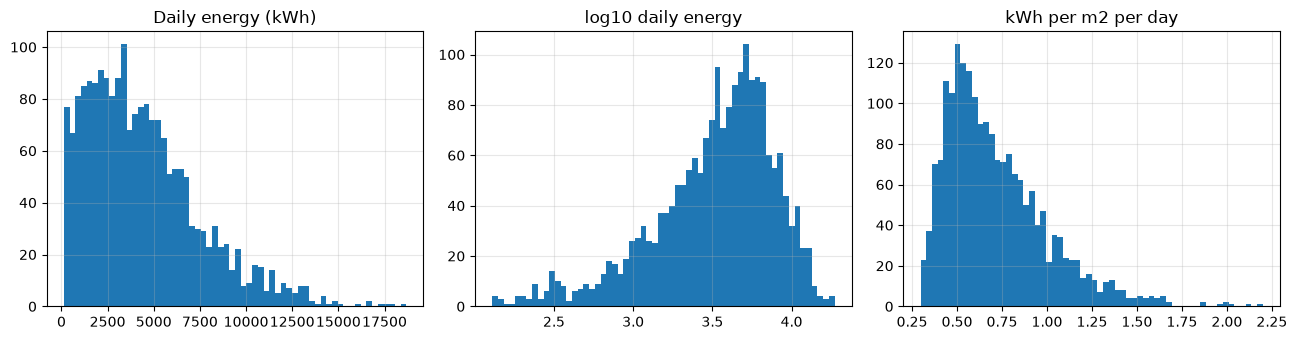

{0.01: 0.327, 0.5: 0.653, 0.99: 1.584}


In [4]:
RES["target_skew"] = float(df[T].skew()); RES["target_log_skew"] = float(np.log1p(df[T]).skew())
RES["target_quantiles"] = df[T].quantile([.01, .25, .5, .75, .99]).round(1).to_dict()
RES["target_cv"] = float(df[T].std() / df[T].mean())
print("skew raw / log1p:", round(RES["target_skew"], 2), round(RES["target_log_skew"], 2), "| CV:", round(RES["target_cv"], 2))
print(RES["target_quantiles"])
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
ax[0].hist(df[T], bins=60); ax[0].set_title("Daily energy (kWh)")
ax[1].hist(np.log10(df[T]), bins=60); ax[1].set_title("log10 daily energy")
df["_eui"] = df[T] / df["floor_area_m2"]
ax[2].hist(df["_eui"].dropna(), bins=60); ax[2].set_title("kWh per m2 per day")
save("fig_target_distribution")
RES["eui_quantiles"] = df["_eui"].quantile([.01, .5, .99]).round(3).to_dict(); print(RES["eui_quantiles"])

## 3. Features and their relation to the target

floor_area_m2             0.857
planned_occupancy         0.688
outdoor_temperature_c     0.286
operating_hours           0.271
window_to_wall_ratio      0.064
cooling_efficiency_cop   -0.062
Name: daily_energy_kwh, dtype: float64

,floor_area_m2,planned_occupancy,operating_hours,outdoor_temperature_c,cooling_efficiency_cop,window_to_wall_ratio
floor_area_m2,1.00,0.78,-0.02,0.02,0.02,0.00
planned_occupancy,0.78,1.00,-0.01,0.02,0.03,0.01
operating_hours,-0.02,-0.01,1.00,0.00,0.02,-0.00
outdoor_temperature_c,0.02,0.02,0.00,1.00,0.04,0.05
cooling_efficiency_cop,0.02,0.03,0.02,0.04,1.00,0.00
window_to_wall_ratio,0.00,0.01,-0.00,0.05,0.00,1.00


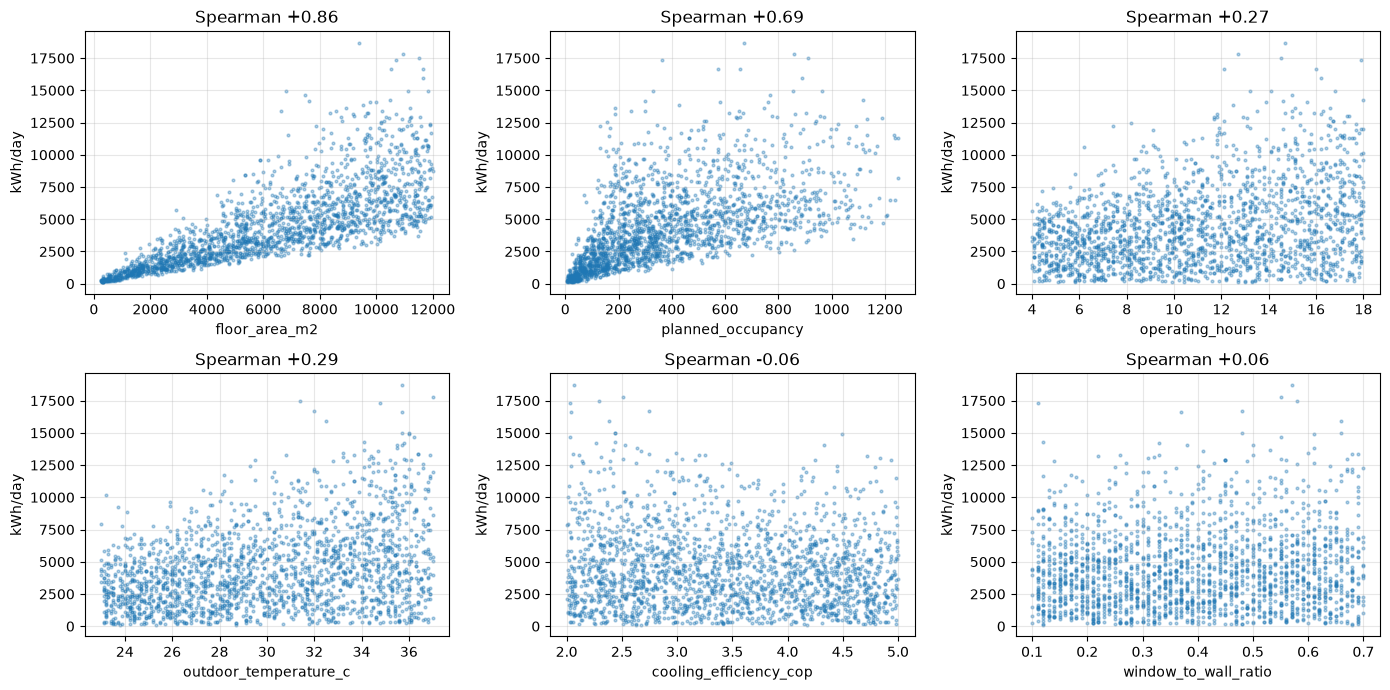

In [5]:
sp = df[NUM + [T]].corr(method="spearman")[T].drop(T).sort_values(ascending=False)
RES["spearman_with_target"] = sp.round(3).to_dict(); display(sp.round(3))
pair = df[NUM].corr(method="spearman").round(2); RES["spearman_area_occupancy"] = float(pair.loc["floor_area_m2", "planned_occupancy"])
display(pair)
fig, ax = plt.subplots(2, 3, figsize=(14, 7))
for a, c in zip(ax.ravel(), NUM):
    a.scatter(df[c], df[T], s=4, alpha=0.35); a.set_xlabel(c); a.set_ylabel("kWh/day")
    a.set_title(f"Spearman {sp[c]:+.2f}")
save("fig_feature_relations")

,n,mean_kwh,median_kwh,median_area,median_eui
building_type,,,,,
Library,511,4076.897,3561.31,5983.6,0.607
Office,514,4493.205,3996.57,6259.9,0.666
Retail,469,5502.740,5020.36,5988.9,0.843
School,506,3595.663,3215.09,6365.7,0.521


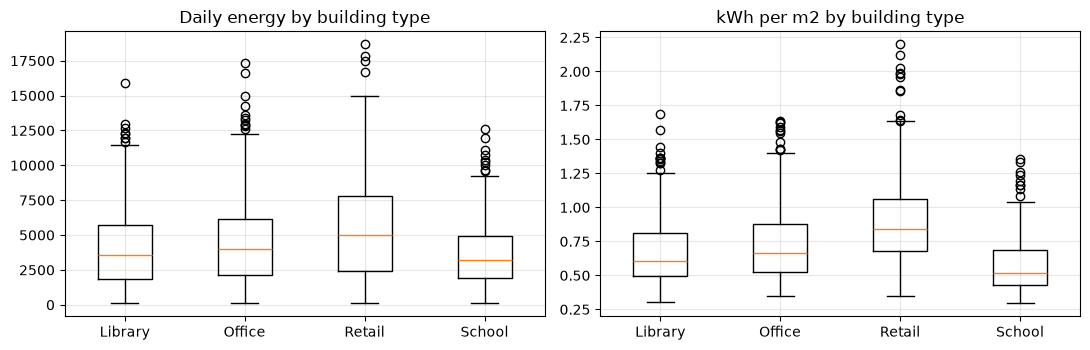

In [6]:
bt = df.groupby("building_type").agg(n=(T, "size"), mean_kwh=(T, "mean"), median_kwh=(T, "median"),
                                      median_area=("floor_area_m2", "median"), median_eui=("_eui", "median"))
display(bt.round(3)); RES["by_type_descriptive"] = bt.round(3).to_dict(orient="index")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].boxplot([df.loc[df.building_type == t, T] for t in bt.index], tick_labels=bt.index); ax[0].set_title("Daily energy by building type")
ax[1].boxplot([df.loc[df.building_type == t, "_eui"].dropna() for t in bt.index], tick_labels=bt.index); ax[1].set_title("kWh per m2 by building type")
save("fig_building_type")

## 4. Train/test split

In [7]:
tr, te = train.split(df)
RES["n_train"], RES["n_test"] = len(tr), len(te)
RES["id_overlap"] = len(set(tr[config.ID_COL]) & set(te[config.ID_COL]))
RES["target_mean_train_test"] = [float(tr[T].mean()), float(te[T].mean())]
RES["missing_in_test"] = {k: int(v) for k, v in te[config.FEATURES].isna().sum().items() if v}
print({k: RES[k] for k in ["n_train", "n_test", "id_overlap", "target_mean_train_test", "missing_in_test"]})
display(pd.concat([tr.building_type.value_counts(normalize=True).rename("train"),
                   te.building_type.value_counts(normalize=True).rename("test")], axis=1).round(3))

{'n_train': 1600, 'n_test': 400, 'id_overlap': 0, 'target_mean_train_test': [4347.83485, 4591.14105], 'missing_in_test': {'floor_area_m2': 3, 'planned_occupancy': 3}}


,train,test
building_type,,
School,0.261,0.222
Library,0.256,0.255
Office,0.254,0.268
Retail,0.229,0.255


## 5. Model comparison (same split, same seed)

In [8]:
X_tr, y_tr, X_te, y_te = tr[config.FEATURES], tr[T], te[config.FEATURES], te[T]
meta = json.load(open(config.MODEL_DIR / "metadata.json"))
fitted, rows = {}, []
for name, mdl in train.candidate_models().items():
    pipe = Pipeline([("prep", train.build_preprocessor()), ("model", mdl)])
    t0 = time.perf_counter(); pipe.fit(X_tr, y_tr); fit_s = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = pipe.predict(X_te); pred_s = time.perf_counter() - t0
    m = train.evaluate(y_te, pred)
    m.update({"median_abs_pct_error": float(np.median(np.abs(pred - y_te) / y_te) * 100),
              "MAE_pct_of_mean": float(m["MAE"] / y_te.mean() * 100),
              "fit_seconds": fit_s, "predict_ms_per_1000": pred_s / len(X_te) * 1e6})
    fitted[name] = (pipe, pred); rows.append({"model": name, **m})
comp = pd.DataFrame(rows).set_index("model").join(pd.DataFrame(meta["cv_results"]).T)
display(comp.round(3)); RES["comparison"] = comp.round(4).to_dict(orient="index")
for name in comp.index:
    assert abs(comp.loc[name, "RMSE"] - meta["test_results"][name]["RMSE"]) < 0.5, name
print("re-run matches models/metadata.json")
saved = joblib.load(config.MODEL_DIR / "model.joblib")
print("saved model reproduces re-fit predictions:", np.allclose(saved.predict(X_te), fitted[meta["selected_model"]][1]))
RES["selected_model"] = meta["selected_model"]
print(open(FIG / "cv_exploration.txt").read() if (FIG / "cv_exploration.txt").exists() else "")

,MAE,RMSE,R2,median_abs_pct_error,MAE_pct_of_mean,fit_seconds,predict_ms_per_1000,cv_RMSE_mean,cv_RMSE_std
model,,,,,,,,,
Baseline (train mean),2515.472,3244.456,-0.006,50.973,54.790,0.203,61.500,3020.003,123.691
Ridge regression,414.996,643.565,0.960,7.516,9.039,0.048,55.560,592.764,31.701
Random forest,529.178,870.500,0.928,9.517,11.526,0.934,348.888,809.270,85.003


re-run matches models/metadata.json
saved model reproduces re-fit predictions: True
Ridge raw          CV RMSE   1439.1 +-   52.6 | CV R2 0.772
Ridge log-target   CV RMSE    592.8 +-   31.7 | CV R2 0.961
RF raw leaf3       CV RMSE    809.3 +-   85.0 | CV R2 0.928
RF raw leaf10      CV RMSE    960.0 +-   93.1 | CV R2 0.898
RF log leaf3       CV RMSE    831.9 +-   74.2 | CV R2 0.924
GBM raw            CV RMSE    712.2 +-   57.9 | CV R2 0.944
GBM log            CV RMSE    619.9 +-   61.4 | CV R2 0.958



## 6. Error analysis (selected model, with the other model for comparison)

{'bias_mean_error_kwh': -29.129752204518464, 'share_overpredicted': 0.4825, 'median_abs_err': 262.69803057104866, 'p90_abs_err': 925.5868848281723, 'share_within_10pct': 0.645, 'share_within_25pct': 0.965}
{0.05: -16.4, 0.25: -7.3, 0.5: -0.4, 0.75: 7.9, 0.95: 22.7}


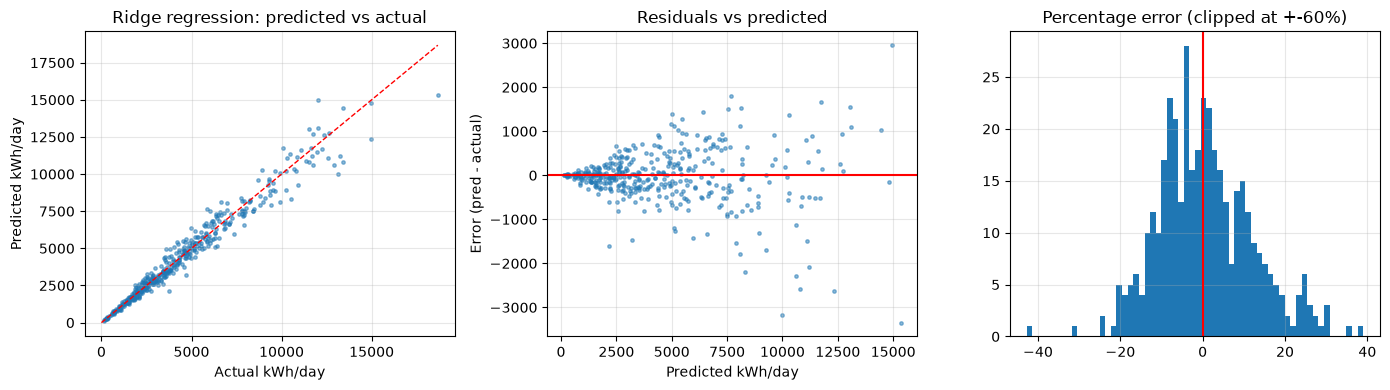

In [9]:
sel = meta["selected_model"]; other = [n for n in fitted if n not in (sel, "Baseline (train mean)")][0]
te = te.copy()
te["pred"] = fitted[sel][1]; te["pred_other"] = fitted[other][1]
te["err"] = te.pred - te[T]; te["abs_err"] = te.err.abs(); te["pct_err"] = te.err / te[T] * 100
RES["bias_mean_error_kwh"] = float(te.err.mean()); RES["share_overpredicted"] = float((te.err > 0).mean())
RES["median_abs_err"] = float(te.abs_err.median()); RES["p90_abs_err"] = float(te.abs_err.quantile(.9))
RES["pct_err_quantiles"] = te.pct_err.quantile([.05, .25, .5, .75, .95]).round(1).to_dict()
RES["share_within_10pct"] = float((te.pct_err.abs() <= 10).mean()); RES["share_within_25pct"] = float((te.pct_err.abs() <= 25).mean())
print({k: RES[k] for k in ["bias_mean_error_kwh", "share_overpredicted", "median_abs_err", "p90_abs_err", "share_within_10pct", "share_within_25pct"]})
print(RES["pct_err_quantiles"])
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
lim = [0, te[T].max()]
ax[0].scatter(te[T], te.pred, s=6, alpha=0.5); ax[0].plot(lim, lim, "r--", lw=1)
ax[0].set_xlabel("Actual kWh/day"); ax[0].set_ylabel("Predicted kWh/day"); ax[0].set_title(f"{sel}: predicted vs actual")
ax[1].scatter(te.pred, te.err, s=6, alpha=0.5); ax[1].axhline(0, color="r"); ax[1].set_xlabel("Predicted kWh/day"); ax[1].set_ylabel("Error (pred - actual)"); ax[1].set_title("Residuals vs predicted")
ax[2].hist(te.pct_err.clip(-60, 60), bins=60); ax[2].axvline(0, color="r"); ax[2].set_title("Percentage error (clipped at +-60%)")
save("fig_pred_vs_actual")


== by_type


,rows,mean_actual,MAE,bias,MAE_other,MAE_pct_of_mean
building_type,,,,,,
Library,102,3830.6,345.2,9.2,384.5,9.0
Office,107,4781.9,434.1,-34.2,543.0,9.1
Retail,102,5677.4,523.7,-28.5,677.4,9.2
School,89,3988.5,347.4,-67.8,508.5,8.7



== by_size


,rows,mean_actual,MAE,bias,MAE_other,MAE_pct_of_mean
size_bin,,,,,,
"(262.199, 2862.1]",80,1302.2,117.9,-54.9,184.9,9.1
"(2862.1, 5138.24]",79,2638.6,243.9,60.0,308.8,9.2
"(5138.24, 7375.84]",79,4600.7,487.8,-27.5,539.8,10.6
"(7375.84, 9616.38]",79,6340.5,564.6,-128.4,695.0,8.9
"(9616.38, 11978.9]",80,8093.9,632.6,48.3,897.3,7.8



== by_hours


...

,rows,mean_actual,MAE,bias,MAE_other,MAE_pct_of_mean
cop_bin,,,,,,
"(1.9, 2.75]",116,4537.0,502.6,-222.2,640.7,11.1
"(2.75, 3.5]",109,4546.3,397.6,21.2,467.1,8.7
"(3.5, 4.25]",88,4603.2,323.7,-4.4,449.8,7.0
"(4.25, 5.1]",87,4707.3,412.3,140.2,538.5,8.8



== by_pred_level


,rows,mean_actual,MAE,bias,MAE_other,MAE_pct_of_mean
pred_bin,,,,,,
"(139.156, 1768.49]",80,1118.5,89.2,-28.7,141.1,8.0
"(1768.49, 3045.922]",80,2445.1,250.1,-5.4,320.2,10.2
"(3045.922, 4891.706]",80,3927.2,324.2,-23.7,406.1,8.3
"(4891.706, 7152.946]",80,5691.1,523.8,107.8,593.9,9.2
"(7152.946, 15330.121]",80,9773.9,887.7,-195.7,1184.6,9.1



== by_missing_input


,rows,mean_actual,MAE,bias,MAE_other,MAE_pct_of_mean
imputed,,,,,,
complete,394,4600.1,409.3,-23.5,528.0,8.9
had a missing input,6,4003.8,786.7,-397.8,607.2,19.6


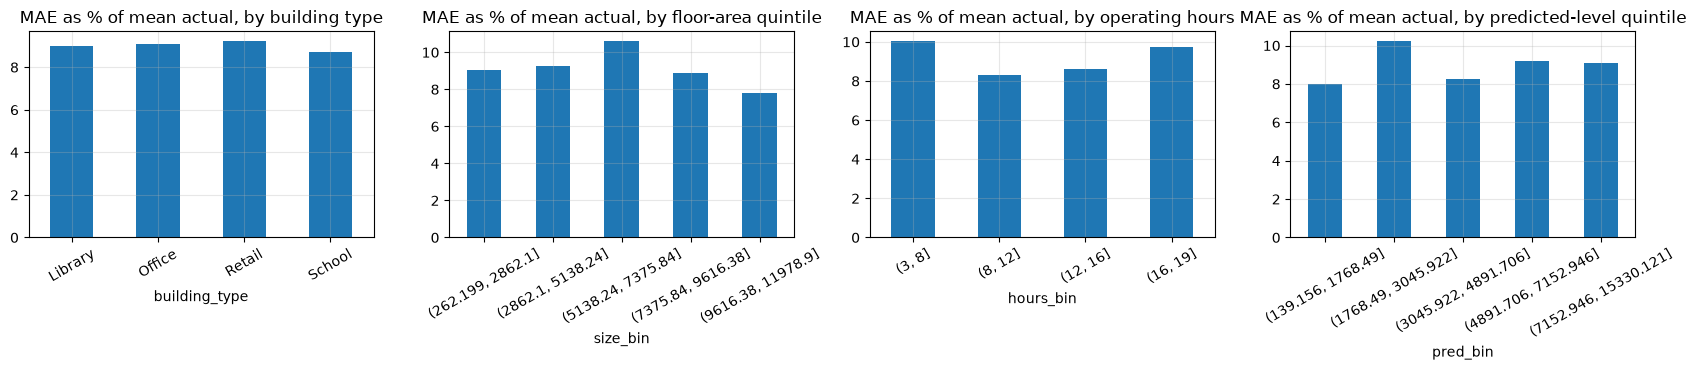

In [10]:
def grp(col):
    g = te.groupby(col, observed=True).agg(rows=(T, "size"), mean_actual=(T, "mean"), MAE=("abs_err", "mean"), bias=("err", "mean"))
    g["MAE_other"] = te.assign(a=(te.pred_other - te[T]).abs()).groupby(col, observed=True)["a"].mean()
    g["MAE_pct_of_mean"] = g.MAE / g.mean_actual * 100
    return g
te["size_bin"] = pd.qcut(te.floor_area_m2, 5, duplicates="drop")
te["hours_bin"] = pd.cut(te.operating_hours, [3, 8, 12, 16, 19])
te["temp_bin"] = pd.cut(te.outdoor_temperature_c, [22, 26, 30, 34, 38])
te["cop_bin"] = pd.cut(te.cooling_efficiency_cop, [1.9, 2.75, 3.5, 4.25, 5.1])
te["pred_bin"] = pd.qcut(te.pred, 5)
te["imputed"] = te[["floor_area_m2", "planned_occupancy"]].isna().any(axis=1).map({True: "had a missing input", False: "complete"})
groups = {"by_type": "building_type", "by_size": "size_bin", "by_hours": "hours_bin", "by_temp": "temp_bin",
          "by_cop": "cop_bin", "by_pred_level": "pred_bin", "by_missing_input": "imputed"}
tables = {}
for n, col in groups.items():
    tables[n] = grp(col); print("\n==", n); display(tables[n].round(1))
    RES[n] = {str(k): v for k, v in tables[n].round(2).to_dict(orient="index").items()}
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
for a, n, t in zip(ax, ["by_type", "by_size", "by_hours", "by_pred_level"], ["building type", "floor-area quintile", "operating hours", "predicted-level quintile"]):
    tables[n]["MAE_pct_of_mean"].plot.bar(ax=a, rot=30); a.set_title(f"MAE as % of mean actual, by {t}")
save("fig_error_by_group")

In [11]:
w = te.reindex(te.abs_err.sort_values(ascending=False).index).head(10)[[config.ID_COL, "building_type"] + NUM + [T, "pred", "err"]]
display(w.round(1)); RES["worst_predictions"] = w.round(1).to_dict(orient="records")
tot = te.abs_err.sum(); k = max(int(len(te) * 0.05), 1)
RES["top5pct_rows_share_of_abs_error"] = float(te.abs_err.nlargest(k).sum() / tot); print("top 5% of rows carry", round(RES["top5pct_rows_share_of_abs_error"], 3), "of total absolute error")

,record_id,building_type,floor_area_m2,planned_occupancy,operating_hours,outdoor_temperature_c,cooling_efficiency_cop,window_to_wall_ratio,daily_energy_kwh,pred,err
100,P04_0101,Retail,9397.4,672.0,14.7,35.7,2.1,0.6,18675.8,15330.1,-3345.7
1731,P04_1732,Retail,9176.9,188.0,11.8,33.2,2.3,0.3,13154.2,9972.3,-3181.9
1546,P04_1547,Retail,10793.3,894.0,16.8,34.7,4.4,0.4,12003.9,14958.6,2954.7
618,P04_0619,Retail,6800.2,331.0,16.8,36.0,2.4,0.7,14960.9,12341.4,-2619.5
1381,P04_1382,Retail,6618.1,247.0,15.0,36.4,2.8,0.7,13385.9,10794.9,-2590.9
744,P04_0745,Office,10358.6,656.0,11.7,35.9,3.2,0.6,12901.2,10620.5,-2280.8
1460,P04_1461,Library,8407.3,130.0,13.6,36.8,4.2,0.7,10506.4,8319.1,-2187.4
354,P04_0355,Office,8348.9,614.0,15.9,36.9,3.2,0.5,13264.0,11187.5,-2076.5
300,P04_0301,School,11807.3,877.0,16.3,25.5,2.1,0.3,5869.0,7672.5,1803.5
210,P04_0211,Retail,6520.0,603.0,13.6,33.4,2.5,0.3,9893.1,8099.5,-1793.6


top 5% of rows carry 0.243 of total absolute error


## 7. What the models use

,coef_log_scale,pct_change_per_1sd
num_log__floor_area_m2,0.794,121.283
cat__building_type_Retail,0.234,26.343
num__operating_hours,0.222,24.909
num__outdoor_temperature_c,0.209,23.276
num__window_to_wall_ratio,0.037,3.761
num_log__planned_occupancy,0.034,3.427
cat__building_type_Office,0.021,2.113
cat__building_type_Library,-0.063,-6.121
num__cooling_efficiency_cop,-0.072,-6.961
cat__building_type_School,-0.192,-17.435


Ridge regression 
 planned_occupancy           29.9
window_to_wall_ratio        89.3
cooling_efficiency_cop     312.9
building_type              750.7
outdoor_temperature_c     1042.9
operating_hours           1192.8
floor_area_m2             2799.1


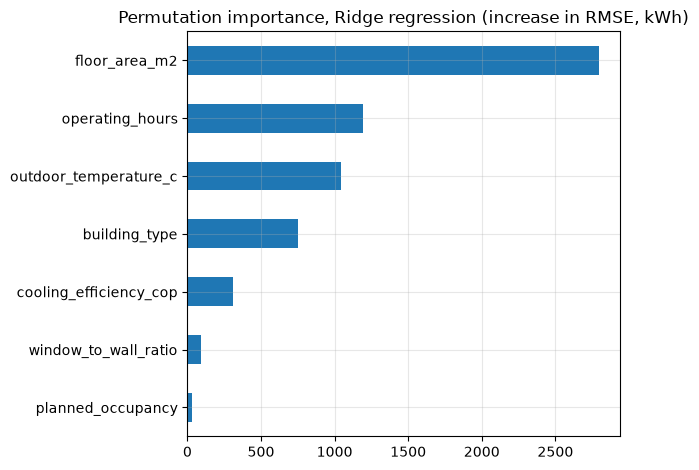

Random forest 
 planned_occupancy           13.7
window_to_wall_ratio        32.8
cooling_efficiency_cop     202.3
building_type              380.5
outdoor_temperature_c      902.5
operating_hours           1028.3
floor_area_m2             2681.4


In [12]:
pipe = fitted[sel][0]
names = pipe.named_steps["prep"].get_feature_names_out()
mdl = pipe.named_steps["model"]
if hasattr(mdl, "regressor_") and hasattr(mdl.regressor_, "coef_"):
    coef = pd.Series(mdl.regressor_.coef_, index=names)
    eff = (np.exp(coef) - 1) * 100   # % change in energy for +1 standard deviation (log-target model)
    out = pd.DataFrame({"coef_log_scale": coef, "pct_change_per_1sd": eff}).sort_values("coef_log_scale", ascending=False)
    display(out.round(3)); RES["ridge_coefficients"] = out.round(4).to_dict(orient="index")
for nm in [sel, other]:
    samp = te
    pi = permutation_importance(fitted[nm][0], samp[config.FEATURES], samp[T], n_repeats=20, random_state=config.SEED,
                                scoring="neg_root_mean_squared_error")
    imp = pd.Series(pi.importances_mean, index=config.FEATURES).sort_values()
    RES[f"permutation_importance_{'selected' if nm == sel else 'other'}"] = imp.round(1).to_dict()
    print(nm, "\n", imp.round(1).to_string())
    if nm == sel:
        imp.plot.barh(title=f"Permutation importance, {nm} (increase in RMSE, kWh)"); save("fig_feature_importance")

In [13]:
with open(FIG / "results.json", "w") as f:
    json.dump(RES, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("saved", FIG / "results.json", "|", sorted(p.name for p in FIG.glob("*.png")))

saved C:\UniMAP\energy-prediction\docs\figures\results.json | ['fig_building_type.png', 'fig_error_by_group.png', 'fig_feature_importance.png', 'fig_feature_relations.png', 'fig_pred_vs_actual.png', 'fig_target_distribution.png']
